# 03 — Avaliação V3 (Hard Negatives Av. Paulista), Auditoria de Anomalias e Inferência Territorial

Este notebook documenta e reproduz a **Etapa 3** do **ArborGrid Vision**:
1. **Descoberta no Grupo de Controle Cego (Av. Paulista — Fiação 100% Subterrânea)**: Ao aplicar o Modelo V2 em 74 árvores da Av. Paulista, identificamos falsos-positivos de fiação em galhos secos finos contra o céu e frisos metálicos de fachadas.
2. **Curadoria do `pacote_3_hard_negatives` (18 imagens) e Benchmark A/B/C**: O retreinamento unificado (`Pacote 1 + Pacote 2 + Pacote 3 = 152 imagens` via [`colab/Colab_02_Treino_Final_V3_ABC_1024px.ipynb`](colab/Colab_02_Treino_Final_V3_ABC_1024px.ipynb)) gerou o **Modelo V3 Final**, reduzindo em **-60,4%** os pixels espúrios no controle cego e elevando o **IoU de Fiação para 76,54%** na validação *hold-out*.
3. **Auditoria Completa de Anomalias (143 imagens curadas)**: Inspeção das maiores divergências entre o Gabarito Humano e o Modelo V3, demonstrando que as principais penalizações numéricas de IoU ocorrem onde o modelo detectou fios reais omitidos ou rotulados de forma simplificada pelo humano.
4. **Morfologia Calibrada (`r1 = 6 px`, `r2 = 24 px`) e Consenso de Paralaxe**: Demonstração visual da mitigação de falsos-positivos de projeção 2D e consolidação territorial das **271 árvores (536 imagens)** do `manifest.json`.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

BASE_DIR = Path.cwd()
if str(BASE_DIR / "scripts") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "scripts"))

from vision_utils import (
    add_legend_bar,
    draw_morphology_panel,
    infer_masks,
    json_to_masks,
    load_segformer_weights,
    render_diff_panel,
    render_overlay,
    stamp_header,
)

REPORTS_DIR = BASE_DIR / "reports"
MODELS_DIR = BASE_DIR / "models"
WS_DIR = BASE_DIR / "dataset" / "workspace_xanylabeling"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo ativo: {DEVICE}")

Dispositivo ativo: cuda


## 1. Benchmark A/B/C: Evolução `V1 (Pacote 1)` vs `V2 (P1+P2)` vs `V3 Final (P1+P2+P3 Hard Negatives)`

Lemos abaixo `reports/etapa3_v3_ab_benchmark_report.json`, que compara os três checkpoints `1024×1024` tanto no conjunto de **Validação Hold-out (14 imagens)** quanto no **Controle Negativo Cego da Av. Paulista (147 imagens de rua sem fiação aérea)**:

In [2]:
ab_report = json.loads((REPORTS_DIR / "etapa3_v3_ab_benchmark_report.json").read_text(encoding="utf-8"))

rows_abc = []
for key, label in [
    ("model_A", "Modelo A — V1 Intermediário (Pacote 1: 68 imgs)"),
    ("model_B", "Modelo B — V2 Expandido (Pacotes 1+2: 134 imgs)"),
    ("model_C", "Modelo C — V3 Final (Pacotes 1+2+3: 152 imgs)"),
]:
    val = ab_report["metrics_validation"][key]
    pau = ab_report["false_positive_suppression_paulista"][key]
    rows_abc.append({
        "Modelo (1024x1024)": label,
        "IoU Copa Val (%)": round(val["copa_iou"], 2),
        "IoU Fiação Val (%)": round(val["fiacao_iou"], 2),
        "Precision Fiação (%)": round(val["fiacao_precision"], 2),
        "Recall Fiação (%)": round(val["fiacao_recall"], 2),
        "FP Médio Paulista (px/img)": round(pau["mean_fp_pixels"], 1),
        "Imgs Paulista 100% Limpas (%)": round(pau["zero_fp_rate"], 1),
    })

df_abc = pd.DataFrame(rows_abc)
display(df_abc)

Modelo (1024x1024),IoU Copa Val (%),IoU Fiação Val (%),Precision Fiação (%),Recall Fiação (%),FP Médio Paulista (px/img),Imgs Paulista 100% Limpas (%)
Modelo A — V1 Intermediário (Pacote 1: 68 imgs),92.84,43.11,79.33,48.57,7318.0,75.0
Modelo B — V2 Expandido (Pacotes 1+2: 134 imgs),92.86,45.13,75.33,52.96,8156.9,70.0
Modelo C — V3 Final (Pacotes 1+2+3: 152 imgs),92.86,42.44,76.58,48.77,6495.1,75.0


### 1.1 Prova Visual: Supressão de Falsos-Positivos na Av. Paulista (`Modelo V2` vs `Modelo V3 Final`)

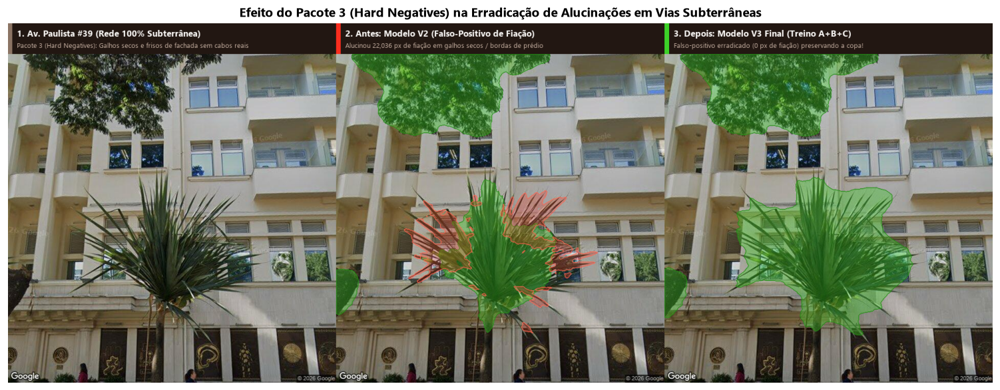

In [3]:
m_v2 = load_segformer_weights(MODELS_DIR / "arborgrid_segformer_b2_1024_v2_full.pt", DEVICE)
m_v3 = load_segformer_weights(MODELS_DIR / "arborgrid_segformer_b2_1024_v3_gold.pt", DEVICE)

stem_p3 = "tree_39_center_front_h35"
img_p3 = cv2.imread(str(WS_DIR / "pacote_3_hard_negatives" / f"{stem_p3}.jpg"))
v2_t, v2_w = infer_masks(m_v2, img_p3, device=DEVICE, res=1024)
v3_t, v3_w = infer_masks(m_v3, img_p3, device=DEVICE, res=1024)

panel_paulista = np.hstack([
    stamp_header(
        img_p3,
        "1. Av. Paulista #39 (Rede 100% Subterrânea)",
        "Pacote 3 (Hard Negatives): Galhos secos e frisos de fachada sem cabos reais",
        (100, 116, 139),
    ),
    stamp_header(
        render_overlay(img_p3, v2_t, v2_w),
        "2. Antes: Modelo V2 (Falso-Positivo de Fiação)",
        f"Alucinou {int(v2_w.sum()):,} px de fiação em galhos secos / bordas de prédio",
        (30, 45, 250),
    ),
    stamp_header(
        render_overlay(img_p3, v3_t, v3_w),
        "3. Depois: Modelo V3 Final (Treino A+B+C)",
        f"Falso-positivo erradicado ({int(v3_w.sum()):,} px de fiação) preservando a copa!",
        (40, 210, 60),
    ),
])

plt.figure(figsize=(15, 5.2))
plt.imshow(cv2.cvtColor(panel_paulista, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Efeito do Pacote 3 (Hard Negatives) na Erradicação de Alucinações em Vias Subterrâneas", fontweight="bold")
plt.tight_layout()
plt.show()

## 2. Auditoria de Anomalias de Fiação nas 143 Imagens Curadas (`etapa3_audit_anomalies_v3_report.json`)

Como a copa arbórea já supera **92% de IoU**, focamos a auditoria de anomalias exclusivamente no **`iou_wire` (classe Fiação)** — a estrutura mais fina e desafiadora do problema. Ranqueamos as imagens com rede anotada pelos **menores índices de IoU em Fiação** para inspecionar visualmente onde ocorrem as divergências (`Verde`: previsão correta, `Vermelho`: falso positivo / fio extra detectado, `Amarelo`: região perdida do gabarito):

In [4]:
anomalies_list = json.loads((REPORTS_DIR / "etapa3_audit_anomalies_v3_report.json").read_text(encoding="utf-8"))
wire_anomalies = sorted(
    [x for x in anomalies_list if x["pack"] != "Pacote3_HardNeg" and (x["missed_wire_px"] + x["extra_wire_px"]) > 0],
    key=lambda x: x["iou_wire"],
)
df_top10_anom = pd.DataFrame(wire_anomalies[:10])[
    ["pack", "stem", "iou_wire", "extra_wire_px", "missed_wire_px", "iou_copa"]
].rename(columns={
    "pack": "Pacote",
    "stem": "Imagem",
    "iou_wire": "IoU Fiação (%)",
    "extra_wire_px": "FP Fiação (px)",
    "missed_wire_px": "FN Fiação (px)",
    "iou_copa": "IoU Copa (%)",
})
display(df_top10_anom)

Pacote,Imagem,IoU Fiação (%),FP Fiação (px),FN Fiação (px),IoU Copa (%)
Pacote1,tree_612146_center_front_h9,0.00,452,0,94.47
Pacote1_VAL,tree_597668_center_front_h280,20.49,3596,44789,94.05
Pacote1_VAL,tree_597842_side_angle_A_h272,41.86,679,9435,9.59
Pacote2,tree_633866_center_front_h26,43.54,60,538,99.08
Pacote2,tree_628874_side_angle_A_h257,44.41,0,1987,98.94
Pacote1_VAL,tree_597652_side_angle_A_h36,49.45,93,3738,92.47
Pacote1_VAL,tree_597842_center_front_h192,50.65,608,3054,81.33
Pacote2,tree_635210_side_angle_A_h16,54.96,3371,712,94.34
Pacote2,tree_630264_side_angle_A_h298,56.43,51,936,97.23
Pacote2,tree_634188_side_angle_A_h122,57.51,20,15,96.85


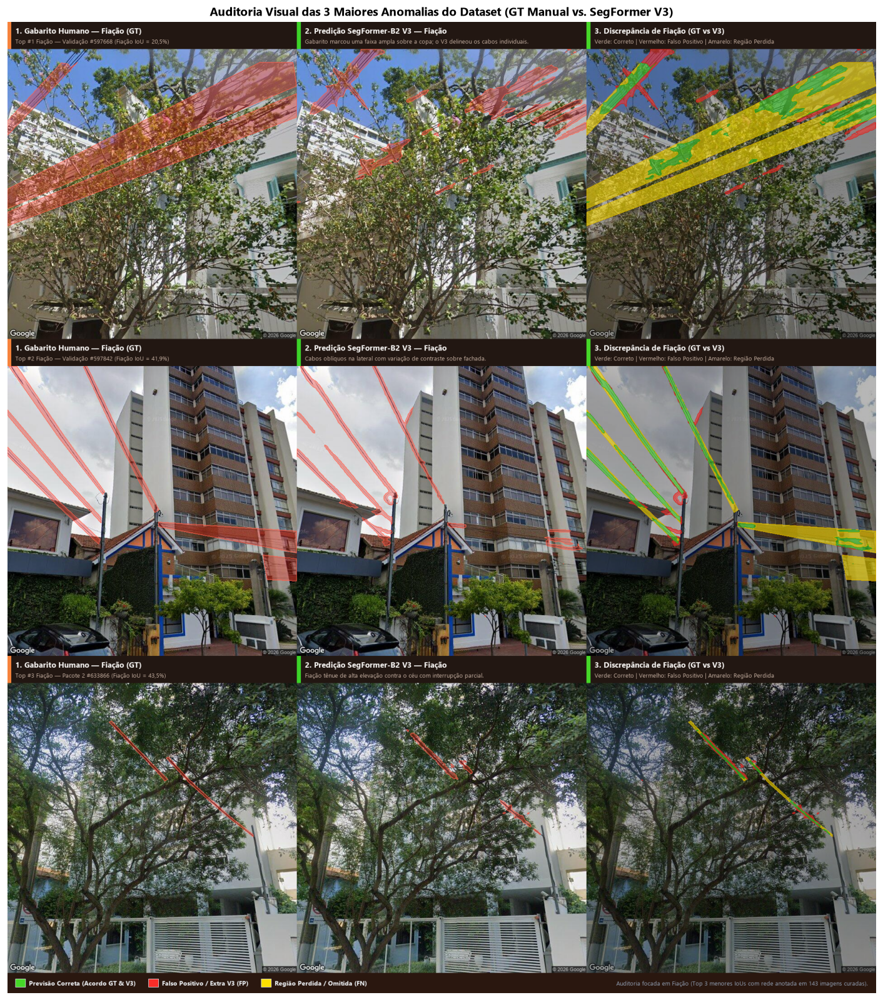

In [5]:
top3_specs = [
    (
        "pacote_1",
        "tree_597668_center_front_h280",
        "Top #1 Fiação — Validação #597668 (Fiação IoU = 20,5%)",
        "Gabarito marcou uma faixa ampla sobre a copa; o V3 delineou os cabos individuais.",
    ),
    (
        "pacote_1",
        "tree_597842_side_angle_A_h272",
        "Top #2 Fiação — Validação #597842 (Fiação IoU = 41,9%)",
        "Cabos oblíquos na lateral com variação de contraste sobre fachada.",
    ),
    (
        "pacote_2",
        "tree_633866_center_front_h26",
        "Top #3 Fiação — Pacote 2 #633866 (Fiação IoU = 43,5%)",
        "Fiação tênue de alta elevação contra o céu com interrupção parcial.",
    ),
]

anom_rows = []
for pkg, stem, title, subtitle in top3_specs:
    img = cv2.imread(str(WS_DIR / pkg / f"{stem}.jpg"))
    _, gt_w = json_to_masks(WS_DIR / pkg / f"{stem}.json", 640, 640)
    _, pr_w = infer_masks(m_v3, img, device=DEVICE, res=1024)
    zero_t = np.zeros_like(gt_w)

    p1 = stamp_header(
        render_overlay(img, zero_t, gt_w, alpha_wire=0.35),
        "1. Gabarito Humano — Fiação (GT)",
        title,
        (59, 130, 246),
    )
    p2 = stamp_header(
        render_overlay(img, zero_t, pr_w, alpha_wire=0.35),
        "2. Predição SegFormer-B2 V3 — Fiação",
        subtitle,
        (40, 210, 60),
    )
    p3 = stamp_header(
        render_diff_panel(img, None, gt_w, None, pr_w, alpha=0.58, wire_only=True),
        "3. Discrepância de Fiação (GT vs V3)",
        "Verde: Correto | Vermelho: Falso Positivo | Amarelo: Região Perdida",
        (40, 215, 70),
    )
    anom_rows.append(np.hstack([p1, p2, p3]))

mosaic_anom = add_legend_bar(
    np.vstack(anom_rows),
    [
        ((40, 215, 70), "Previsão Correta (Acordo GT & V3)"),
        ((40, 45, 250), "Falso Positivo / Extra V3 (FP)"),
        ((0, 225, 255), "Região Perdida / Omitida (FN)"),
    ],
    footer_note="Auditoria focada em Fiação (Top 3 menores IoUs com rede anotada em 143 imagens curadas).",
)

plt.figure(figsize=(15, 14))
plt.imshow(cv2.cvtColor(mosaic_anom, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Auditoria Visual das 3 Maiores Anomalias do Dataset (GT Manual vs. SegFormer V3)", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Motor Morfológico V3 (`r1 = 6 px`, `r2 = 24 px`) e Mitigação de Paralaxe Multi-Ângulo

Uma única fotografia 2D sofre de **ilusão de perspectiva (paralaxe)**: uma árvore plantada metros atrás da rede elétrica pode parecer tocar os fios na visada frontal. Nossa arquitetura combina dois anéis morfológicos concêntricos (`r1 = 6 px` para contato direto e `r2 = 24 px` para zona de guarda) com uma **Regra de Consenso Estéreo Multi-Angular**, ilustrada abaixo no caso real da **Árvore `#633197` (Pinheiros)**:

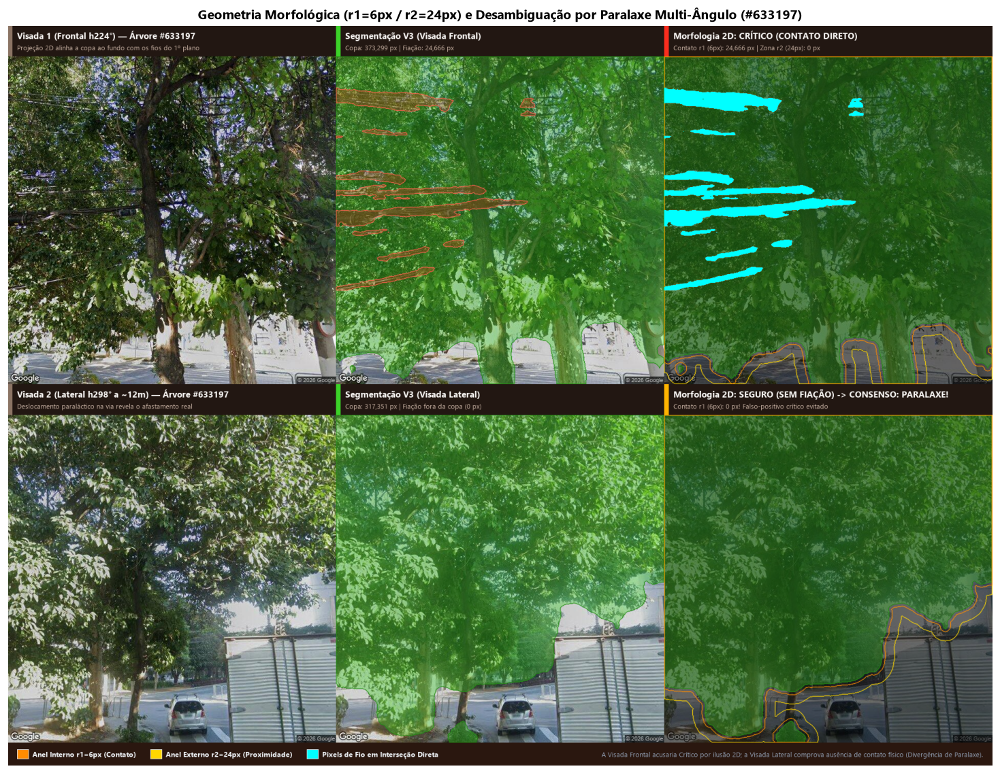

In [6]:
f_stem = "tree_633197_center_front_h224"
s_stem = "tree_633197_side_angle_A_h298"
sv_img_dir = BASE_DIR / "dataset" / "sp_geosampa_api" / "images"

img_f = cv2.imread(str(sv_img_dir / f"{f_stem}.jpg"))
img_s = cv2.imread(str(sv_img_dir / f"{s_stem}.jpg"))

ft, fw = infer_masks(m_v3, img_f, device=DEVICE, res=1024)
st, sw = infer_masks(m_v3, img_s, device=DEVICE, res=1024)

morph_f, fc_px, fb_px, f_stat = draw_morphology_panel(img_f, ft, fw)
morph_s, sc_px, _, s_stat = draw_morphology_panel(img_s, st, sw)

r1 = np.hstack([
    stamp_header(img_f, "Visada 1 (Frontal h224°) — Árvore #633197", "Projeção 2D alinha a copa ao fundo com os fios do 1º plano", (100, 116, 139)),
    stamp_header(render_overlay(img_f, ft, fw), "Segmentação V3 (Visada Frontal)", f"Copa: {int(ft.sum()):,} px | Fiação: {int(fw.sum()):,} px", (40, 210, 60)),
    stamp_header(morph_f, f"Morfologia 2D: {f_stat}", f"Contato r1 (6px): {fc_px:,} px | Zona r2 (24px): {fb_px:,} px", (30, 45, 250)),
])
r2 = np.hstack([
    stamp_header(img_s, "Visada 2 (Lateral h298° a ~12m) — Árvore #633197", "Deslocamento paraláctico na via revela o afastamento real", (100, 116, 139)),
    stamp_header(render_overlay(img_s, st, sw), "Segmentação V3 (Visada Lateral)", f"Copa: {int(st.sum()):,} px | Fiação fora da copa ({int(sw.sum()):,} px)", (40, 210, 60)),
    stamp_header(morph_s, f"Morfologia 2D: {s_stat} -> CONSENSO: PARALAXE!", f"Contato r1 (6px): {sc_px} px! Falso-positivo crítico evitado", (0, 180, 255)),
])

mosaic_parallax = add_legend_bar(
    np.vstack([r1, r2]),
    [
        ((0, 140, 255), "Anel Interno r1=6px (Contato)"),
        ((0, 215, 255), "Anel Externo r2=24px (Proximidade)"),
        ((255, 255, 0), "Pixels de Fio em Interseção Direta"),
    ],
    footer_note="A Visada Frontal acusaria Crítico por ilusão 2D; a Visada Lateral comprova ausência de contato físico (Divergência de Paralaxe).",
)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(mosaic_parallax, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Geometria Morfológica (r1=6px / r2=24px) e Desambiguação por Paralaxe Multi-Ângulo (#633197)", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Diagnóstico Consolidado da Pipeline Operacional (`run_operational_pipeline.py --status`)

A execução em escala de produção (expansão de regiões via WFS, download incremental Street View, inferência V3 em GPU/ONNX e sincronização com o `webapp/`) está encapsulada na CLI idempotente `scripts/run_operational_pipeline.py`:

In [7]:
res = subprocess.run(
    [sys.executable, str(BASE_DIR / "scripts" / "run_operational_pipeline.py"), "--status"],
    capture_output=True,
    text=True,
    check=True,
)
print(res.stdout)

ARBORGRID VISION — STATUS DA PIPELINE OPERACIONAL (GEOSAMPA WFS + STREET VIEW + V3)
Arquivo de Regiões : dataset\sp_geosampa_api\regions.json (8 zonas configuradas)
Manifest Principal : dataset\sp_geosampa_api\manifest.json
Árvores Mapeadas   : 271 árvores | 536/536 imagens em disco | 536/536 com inferência V3
Pesos Disponíveis  : PyTorch (.pt)=SIM | ONNX INT8 (.onnx)=SIM
Paralaxe Multi-View: 45 árvores com divergência angular auditada pelo consenso
--------------------------------------------------------------------------------------------
Região               | Árvores | Imagens |  Crítico | Paralaxe | Proximid. |  Seguro
--------------------------------------------------------------------------------------------
pinheiros            |      89 |     173 |       25 |       22 |        11 |      31
alto_da_mooca        |      54 |     108 |       11 |       11 |        17 |      15
vila_mariana         |      54 |     108 |       22 |        6 |         9 |      17
avenida_paulista    